# Population raster + flight trajectories

A spike raster (`n_neurons` x `n_timepoints`) with black tick marks for **two
flights** from a single high-neuron-count session (`Dataset_3_14543_240420`,
289 units), plus the matching `(x, y, z)` position traces.

Spikes come straight from `bat_data_loader` (binned counts); we use a fine
`BIN_WIDTH` so the raster reads as tick marks rather than blocks. Each
`split_each_trajectory_flag=True` batch element is one full flight (padded), so
we trim with `batch.mask`. The two flights are kept as separate entries along
an (imaginary) **batch axis** — drawn as side-by-side panels rather than glued
together in time — and neurons are shown in **native order** (no sorting).

In [10]:
%load_ext autoreload
%autoreload 2

import os
import sys

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers 3d projection)

sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))
from digitalbat.datasets.data import bat_data_loader
from digitalbat.datasets.defaults import make_data_config

sns.set_theme(context='notebook', style='ticks')

SESSION   = 'Dataset_3_14543_240420'
SPLIT     = 'test'                     # which loader split to pull flights from
BIN_WIDTH = 0.02                       # s; fine bins -> tick-like raster
FLIGHT_SEL = [0, 1]                    # indices (into the collected flight list) to stack

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
# `split_each_trajectory_flag=True` (the make_data_config default) => one full
# flight per batch element, padded to the longest flight and trimmed via mask.
cfg = make_data_config(session_names=[SESSION])
cfg['bin_width'] = BIN_WIDTH

dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**cfg)
n_neurons = unit_num_dict[SESSION]
print(f'{SESSION}: {n_neurons} neurons, behavior_dim={behavior_dim}, bin={BIN_WIDTH*1e3:.0f} ms')

  Acceleration filter: removed 6/136 flights (peak |acc| > 50 m/s²)
Dataset_3_14543_240420: 126 neurons, behavior_dim=3, bin=20 ms


In [12]:
# Collect every flight in the chosen split as (T_valid, .) arrays (padding removed).
# behavior columns are [x, y, z]; spike is per-bin counts (n_neurons wide).
flights = []
for batch in dataloaders[SPLIT][SESSION]:
    for i in range(batch.behavior.shape[0]):
        valid = batch.mask[i].numpy() == 1.0
        flights.append(dict(
            behavior=batch.behavior[i].numpy()[valid],   # (T, 3) -> x, y, z
            spike=batch.spike[i].numpy()[valid],         # (T, n_neurons)
            flight_path_index=int(batch.flight_path_index[i]),
            flight_type_index=int(batch.flight_type_index[i]),
        ))

print(f'{len(flights)} flights in {SPLIT!r} split')
for k, f in enumerate(flights):
    T = f['behavior'].shape[0]
    print(f'  [{k}] path={f["flight_path_index"]:>3}  type={f["flight_type_index"]:>3}  '
          f'T={T:>3} ({T*BIN_WIDTH:4.1f}s)  spikes={int(f["spike"].sum())}')

20 flights in 'test' split
  [0] path= 34  type=  4  T=102 ( 2.0s)  spikes=1230
  [1] path= 15  type=  3  T=118 ( 2.4s)  spikes=1334
  [2] path= 36  type=  4  T=101 ( 2.0s)  spikes=1208
  [3] path=103  type= 15  T=100 ( 2.0s)  spikes=1179
  [4] path=  0  type=  1  T=217 ( 4.3s)  spikes=2334
  [5] path= 56  type=  4  T= 98 ( 2.0s)  spikes=1200
  [6] path= 11  type=  3  T=117 ( 2.3s)  spikes=1148
  [7] path= 42  type=  4  T=105 ( 2.1s)  spikes=1245
  [8] path= 84  type= 14  T=108 ( 2.2s)  spikes=1225
  [9] path= 63  type= 10  T=263 ( 5.3s)  spikes=1754
  [10] path= 10  type=  3  T=115 ( 2.3s)  spikes=1135
  [11] path= 33  type=  4  T=102 ( 2.0s)  spikes=1133
  [12] path=124  type= 15  T=107 ( 2.1s)  spikes=1339
  [13] path= 68  type= 14  T=111 ( 2.2s)  spikes=1158
  [14] path= 76  type= 14  T=104 ( 2.1s)  spikes=1214
  [15] path= 81  type= 14  T=121 ( 2.4s)  spikes=1451
  [16] path=102  type= 15  T= 97 ( 1.9s)  spikes=1182
  [17] path= 93  type= 15  T=106 ( 2.1s)  spikes=1385
  [18] path

In [13]:
# --- Stack the selected flights along an (imaginary) batch axis (no time stitching) ---
sel       = [flights[i] for i in FLIGHT_SEL]
n_flights = len(sel)
lengths   = [f['spike'].shape[0] for f in sel]
T_max     = max(lengths)

# (n_flights, T_max, .) batch tensors; padding past each flight's valid length
# (spikes -> 0, behavior -> NaN) is never plotted, we slice each flight to its length.
spike_batch = np.zeros((n_flights, T_max, n_neurons))
beh_batch   = np.full((n_flights, T_max, 3), np.nan)
for b, f in enumerate(sel):
    L = lengths[b]
    spike_batch[b, :L] = f['spike']
    beh_batch[b, :L]   = f['behavior']

t = np.arange(T_max) * BIN_WIDTH  # within-flight time axis (s), shared across panels

print('batch:', spike_batch.shape, '| flight lengths (bins):', lengths)

batch: (2, 118, 126) | flight lengths (bins): [102, 118]


## Raster

One row per neuron (**native order**, unsorted), one tick per bin containing a
spike. The two flights are stacked vertically with a shared x-axis, so the time
scale is identical across panels and a shorter flight simply ends earlier.

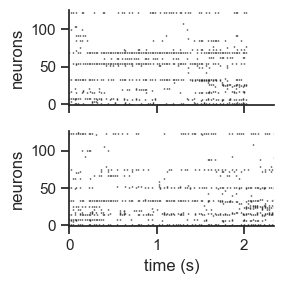

In [14]:
fig, axes = plt.subplots(n_flights, 1, figsize=(3, 1.5 * n_flights),
                         sharex=True, sharey=True, squeeze=False)
axes = axes[:, 0]

for b, ax in enumerate(axes):
    L = lengths[b]
    raster = spike_batch[b, :L].T            # (n_neurons, L), native neuron order
    tb = t[:L]
    positions = [tb[raster[i] > 0] for i in range(n_neurons)]
    ax.eventplot(positions, colors='black', lineoffsets=np.arange(n_neurons),
                 linelengths=0.9, linewidths=1.0)
    ax.set_ylim(-1, n_neurons)
    ax.set_ylabel('neurons')
    # ax.set_title(f'flight {FLIGHT_SEL[b]} (path {sel[b]["flight_path_index"]})')
    sns.despine(ax=ax)

axes[-1].set_xlim(0, t[-1])                  # shared T_max span -> constant time scale
axes[-1].set_xlabel('time (s)')
# fig.suptitle(f'{SESSION}: {n_neurons} neurons x {BIN_WIDTH*1e3:.0f} ms bins '
#              f'-- two flights stacked along the batch axis')
plt.tight_layout()
plt.savefig(f'./out/joint/flight_raster_{SESSION}.pdf', bbox_inches='tight')
plt.show()

## Position over time

The `(x, y, z)` coordinates for the same two flights, overlaid on one set of
axes per flight, stacked vertically with a shared x-axis so the time scale
matches the raster.

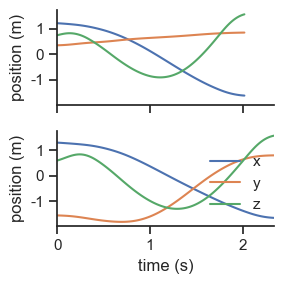

In [15]:
fig, axes = plt.subplots(n_flights, 1, figsize=(3, 1.5 * n_flights),
                         sharex=True, sharey=True, squeeze=False)
axes = axes[:, 0]
labels = ['x', 'y', 'z']
colors = sns.color_palette('deep', 3)

for b, ax in enumerate(axes):
    L = lengths[b]
    for j in range(3):
        ax.plot(t[:L], beh_batch[b, :L, j], color=colors[j], lw=1.5, label=labels[j])
    ax.set_ylabel('position (m)')
    # ax.set_title(f'flight {FLIGHT_SEL[b]} (path {sel[b]["flight_path_index"]})')
    sns.despine(ax=ax)
axes[1].legend(loc='lower right', ncol=1, frameon=False)

axes[-1].set_xlim(0, t[-1])                  # shared T_max span -> constant time scale
axes[-1].set_xlabel('time (s)')
# fig.suptitle(f'{SESSION}: position per flight')
plt.tight_layout()
plt.savefig(f'./out/joint/beh_{SESSION}.pdf', bbox_inches='tight')
plt.show()

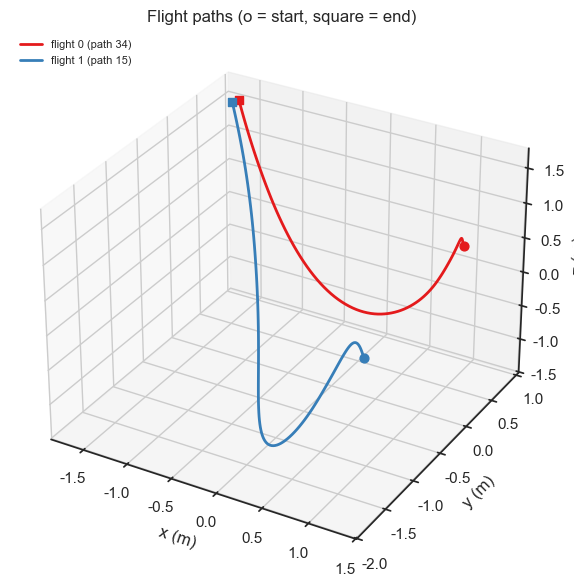

In [16]:
# 3D view of the same two trajectories in the arena.
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
flight_colors = sns.color_palette('Set1', n_flights)

for b in range(n_flights):
    L = lengths[b]
    seg = beh_batch[b, :L]
    ax.plot(seg[:, 0], seg[:, 1], seg[:, 2], color=flight_colors[b], lw=2,
            label=f'flight {FLIGHT_SEL[b]} (path {sel[b]["flight_path_index"]})')
    ax.scatter(*seg[0], color=flight_colors[b], marker='o', s=40)   # start
    ax.scatter(*seg[-1], color=flight_colors[b], marker='s', s=40)  # end

ax.set_xlabel('x (m)'); ax.set_ylabel('y (m)'); ax.set_zlabel('z (m)')
ax.set_title('Flight paths (o = start, square = end)')
ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

## All flights, colored by cluster

Every flight in the session (all of `train`/`valid`/`test`) drawn in 3D and
colored by its flight cluster (`flight_type_index`), so the set of stereotyped
trajectory types is visible at a glance.

130 flights across all splits, 19 clusters


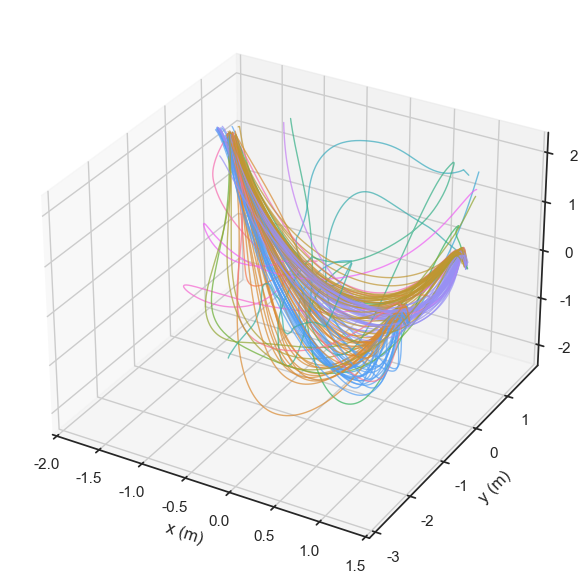

In [17]:
# Collect every flight across all splits (padding removed), keeping cluster id.
all_flights = []
for split in dataloaders:
    for batch in dataloaders[split][SESSION]:
        for i in range(batch.behavior.shape[0]):
            valid = batch.mask[i].numpy() == 1.0
            all_flights.append(dict(
                behavior=batch.behavior[i].numpy()[valid],   # (T, 3) -> x, y, z
                flight_type_index=int(batch.flight_type_index[i]),
            ))

clusters = sorted({f['flight_type_index'] for f in all_flights})
palette  = dict(zip(clusters, sns.color_palette('husl', len(clusters))))
print(f'{len(all_flights)} flights across all splits, {len(clusters)} clusters')

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
seen = set()
for f in all_flights:
    c = f['flight_type_index']
    seg = f['behavior']
    ax.plot(seg[:, 0], seg[:, 1], seg[:, 2], color=palette[c], lw=1.0, alpha=0.7,
            label=f'cluster {c}' if c not in seen else None)
    seen.add(c)

ax.set_xlabel('x (m)'); ax.set_ylabel('y (m)'); ax.set_zlabel('z (m)')
# ax.set_title(f'{SESSION}: all flights by cluster')
# ax.legend(loc='upper left', fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(f'./out/joint/all_flights_by_cluster_{SESSION}.pdf', bbox_inches='tight')
plt.show()

## All neurons, smoothed and sorted (Rastermap)

Every neuron's activity over **all flights** (concatenated across splits) shown
as a smoothed population image, with neurons reordered by
[Rastermap](https://github.com/MouseLand/rastermap) so that neurons with
similar activity sit near each other. Vertical lines mark flight boundaries.

population matrix: 126 neurons x 15187 bins (130 flights)


/home/alowet/Documents/code/rastermap/rastermap/rastermap.py:278: RuntimeWarning: invalid value encountered in divide
  X /= stdx[:,np.newaxis]
/home/alowet/Documents/code/rastermap/rastermap/cluster.py:138: UserWarning: found fewer than half the n_clusters that the user specified, rerunning with random initialization
  warnings.warn(
/home/alowet/Documents/code/rastermap/rastermap/cluster.py:148: UserWarning: found fewer clusters than user specified, try reducing n_clusters and/or reduce n_splits and/or increase n_PCs
  warnings.warn(


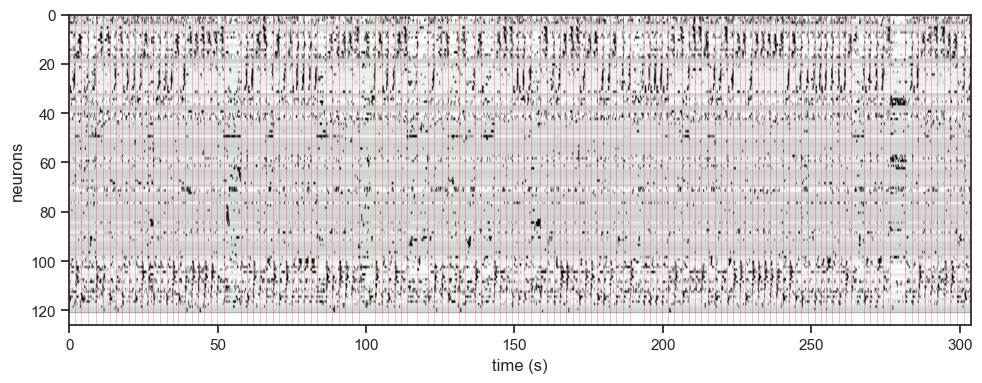

In [19]:
sys.path.append(os.path.expanduser('~/Documents/code/rastermap'))
from rastermap import Rastermap
from scipy.ndimage import gaussian_filter1d
from scipy.stats import zscore

SMOOTH_SIGMA = 3   # gaussian sigma in bins (60 ms at 20 ms bins) for the display

# Concatenate every flight (all splits) into one (n_neurons, T_total) matrix,
# recording flight boundaries for the vertical guides.
spike_segs, bounds = [], [0]
for split in dataloaders:
    for batch in dataloaders[split][SESSION]:
        for i in range(batch.behavior.shape[0]):
            valid = batch.mask[i].numpy() == 1.0
            spike_segs.append(batch.spike[i].numpy()[valid])   # (T, n_neurons)
            bounds.append(bounds[-1] + int(valid.sum()))
spks = np.concatenate(spike_segs, axis=0).T.astype('float32')  # (n_neurons, T_total)
print(f'population matrix: {spks.shape[0]} neurons x {spks.shape[1]} bins '
      f'({len(spike_segs)} flights)')

# Rastermap sort (fit on the raw spikes; it normalizes internally).
model = Rastermap(n_clusters=50, n_PCs=min(64, spks.shape[0] - 1),
                  locality=0.75, time_lag_window=5, verbose=False).fit(spks)
isort = model.isort

# Smooth across time, z-score per neuron, then reorder rows by the sort.
disp = zscore(gaussian_filter1d(spks, SMOOTH_SIGMA, axis=1), axis=1)[isort]

fig, ax = plt.subplots(figsize=(10, 4))
t_total = spks.shape[1] * BIN_WIDTH
ax.imshow(disp, vmin=-0.5, vmax=2.0, cmap='gray_r', aspect='auto',
          extent=[0, t_total, n_neurons, 0])
for b in bounds[1:-1]:
    ax.axvline(b * BIN_WIDTH, color='tab:red', lw=0.4, alpha=0.5)
ax.set_xlabel('time (s)')
ax.set_ylabel('neurons')
# ax.set_title(f'{SESSION}: all neurons, smoothed + Rastermap-sorted')
plt.tight_layout()
plt.savefig(f'./out/joint/rastermap_{SESSION}.pdf', bbox_inches='tight')
plt.show()